In [2]:
import pandas as pd

print("Pandas version:", pd.__version__)
print("Pandas installed successfully!")

Pandas version: 3.1.0
Pandas installed successfully!


In [3]:
import os

DATA_PATH = "../data/raw"

files = os.listdir(DATA_PATH)

print("Total files:", len(files))

for file in files:
    print(file)

Total files: 18
accounts.csv
account_status_history.csv
agents.csv
agent_sessions.csv
borrowers.csv
calls.csv
call_attempts.csv
call_dispositions.csv
campaigns.csv
complaints.csv
daily_targeting.csv
data_dictionary.csv
field_visits.csv
payments.csv
promises_to_pay.csv
sms_events.csv
vendor_telephony.csv
whatsapp_events.csv


In [4]:
import pandas as pd

# Load the payments dataset
payments = pd.read_csv("../data/raw/payments.csv")

# Display dataset information
print("PAYMENTS DATASET ANALYSIS")
print("-------------------------")

# Number of rows and columns
print("Dataset shape:", payments.shape)

# Display column names
print("\nColumn names:")
print(payments.columns.tolist())

# Display first 5 records
print("\nFirst 5 records:")
display(payments.head())

# Check data types and missing values
print("\nDataset information:")
payments.info()

PAYMENTS DATASET ANALYSIS
-------------------------
Dataset shape: (25500, 9)

Column names:
['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']

First 5 records:


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
0,PAYMENT0000001,ACC0015539,BRW0011363,2026-02-27 01:28:12,TXN0000007457,22433.23,FAILED,CARD,VND0000001
1,PAYMENT0000002,ACC0004445,BRW0011306,2026-07-23 20:25:20,TXN0000030016,23295.11,FAILED,UPI,VND0000004
2,PAYMENT0000003,ACC0003853,BRW0002549,2026-01-11 21:27:46,TXN0000010466,118814.97,FAILED,NACH,VND0000013
3,PAYMENT0000004,ACC0017531,BRW0006618,2026-06-16 02:35:21,TXN0000031781,145082.17,REVERSED,CASH,VND0000013
4,PAYMENT0000005,ACC0001770,BRW0011492,2026-03-03 06:08:23,TXN0000059257,115148.46,SUCCESS,NETBANKING,VND0000013



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 25500 entries, 0 to 25499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   payment_id         25500 non-null  str    
 1   account_id         25500 non-null  str    
 2   borrower_id        25500 non-null  str    
 3   event_at           25500 non-null  str    
 4   payment_reference  25118 non-null  str    
 5   amount             25500 non-null  float64
 6   payment_status     25500 non-null  str    
 7   payment_method     25500 non-null  str    
 8   provider_id        25500 non-null  str    
dtypes: float64(1), str(8)
memory usage: 3.9 MB


In [5]:
# Check missing values
print("Missing values:")
display(payments.isnull().sum())

# Check exact duplicate rows
print("\nExact duplicate rows:")
print(payments.duplicated().sum())

# Check number of unique values
print("\nUnique values in each column:")
display(payments.nunique())

Missing values:


payment_id             0
account_id             0
borrower_id            0
event_at               0
payment_reference    382
amount                 0
payment_status         0
payment_method         0
provider_id            0
dtype: int64


Exact duplicate rows:
486

Unique values in each column:


payment_id           25000
account_id           16934
borrower_id          10474
event_at             24984
payment_reference    20821
amount               24979
payment_status           4
payment_method           5
provider_id             15
dtype: int64

In [6]:
# 1. Check missing values
print("MISSING VALUES")
print(payments.isnull().sum())

# 2. Check exact duplicate rows
print("\nEXACT DUPLICATE ROWS")
print(payments.duplicated().sum())

# 3. Check unique values
print("\nUNIQUE VALUES")
print(payments.nunique())

# 4. Check numerical summary
print("\nNUMERICAL SUMMARY")
display(payments.describe())

MISSING VALUES
payment_id             0
account_id             0
borrower_id            0
event_at               0
payment_reference    382
amount                 0
payment_status         0
payment_method         0
provider_id            0
dtype: int64

EXACT DUPLICATE ROWS
486

UNIQUE VALUES
payment_id           25000
account_id           16934
borrower_id          10474
event_at             24984
payment_reference    20821
amount               24979
payment_status           4
payment_method           5
provider_id             15
dtype: int64

NUMERICAL SUMMARY


,amount
count,25500.000000
mean,75186.612437
std,43496.079777
min,103.680000
25%,37234.580000
50%,75159.700000
75%,112925.542500
max,149993.550000


In [7]:
# 1. Check payment status
print("PAYMENT STATUS COUNTS")
display(payments["payment_status"].value_counts(dropna=False))

# 2. Check payment methods
print("\nPAYMENT METHODS")
display(payments["payment_method"].value_counts(dropna=False))

# 3. Check repeated payment IDs
print("\nREPEATED PAYMENT IDs")
display(
    payments[
        payments.duplicated("payment_id", keep=False)
    ].sort_values("payment_id").head(20)
)

# 4. Check repeated payment references
print("\nREPEATED PAYMENT REFERENCES")
display(
    payments[
        payments["payment_reference"].notna()
        & payments.duplicated("payment_reference", keep=False)
    ].sort_values("payment_reference").head(20)
)

# 5. Check date range
payments["event_at"] = pd.to_datetime(
    payments["event_at"],
    errors="coerce",
    utc=True
)

print("\nPAYMENT DATE RANGE")
print("Start:", payments["event_at"].min())
print("End:", payments["event_at"].max())

PAYMENT STATUS COUNTS


payment_status
SUCCESS     17880
FAILED       3744
PENDING      2592
REVERSED     1284
Name: count, dtype: int64


PAYMENT METHODS


payment_method
CARD          5227
NACH          5158
NETBANKING    5059
UPI           5052
CASH          5004
Name: count, dtype: int64


REPEATED PAYMENT IDs


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
55,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
25035,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
75,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
25408,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
107,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
25481,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
148,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
25099,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
198,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012
25330,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012



REPEATED PAYMENT REFERENCES


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
551,PAYMENT0000552,ACC0021942,BRW0011343,2026-08-06 18:56:06,TXN0000000009,11792.14,SUCCESS,UPI,VND0000012
25010,PAYMENT0000552,ACC0021942,BRW0011343,2026-08-06 18:56:06,TXN0000000009,11792.14,SUCCESS,UPI,VND0000012
1387,PAYMENT0001388,ACC0019483,BRW0003324,2026-01-31 05:00:49,TXN0000000027,53610.92,FAILED,CARD,VND0000005
3477,PAYMENT0003478,ACC0022277,BRW0011422,2026-06-09 12:22:41,TXN0000000027,43010.39,SUCCESS,NACH,VND0000010
2884,PAYMENT0002885,ACC0021199,BRW0008425,2026-05-03 23:45:49,TXN0000000032,104969.97,SUCCESS,NACH,VND0000007
5306,PAYMENT0005307,ACC0003975,BRW0007408,2026-05-24 14:49:16,TXN0000000032,18086.24,PENDING,CARD,VND0000003
21182,PAYMENT0021183,ACC0011292,BRW0006242,2026-04-10 12:10:27,TXN0000000032,15714.97,SUCCESS,CASH,VND0000005
2839,PAYMENT0002840,ACC0022601,BRW0006594,2026-02-01 22:47:46,TXN0000000113,1139.66,SUCCESS,CARD,VND0000003
13292,PAYMENT0013293,ACC0019961,BRW0006917,2026-01-17 20:51:05,TXN0000000113,55554.44,REVERSED,CARD,VND0000007
18917,PAYMENT0018918,ACC0012876,BRW0010206,2026-08-03 02:17:02,TXN0000000113,101681.86,SUCCESS,CARD,VND0000010



PAYMENT DATE RANGE
Start: 2026-01-01 00:14:40+00:00
End: 2026-08-08 23:50:23+00:00


In [8]:
# Create a copy for analysis
payment_analysis = payments.copy()

# Extract month
payment_analysis["month"] = (
    payment_analysis["event_at"].dt.to_period("M").astype(str)
)

# Calculate payment records and amounts by month and status
monthly_summary = (
    payment_analysis
    .groupby(["month", "payment_status"])
    .agg(
        transaction_count=("payment_id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

# Display results
display(monthly_summary)

C:\Users\Vani\AppData\Local\Temp\ipykernel_9212\557440831.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  payment_analysis["event_at"].dt.to_period("M").astype(str)


,month,payment_status,transaction_count,total_amount
0,2026-01,FAILED,528,3.899211e+07
1,2026-01,PENDING,384,2.919541e+07
2,2026-01,REVERSED,176,1.179726e+07
3,2026-01,SUCCESS,2515,1.911333e+08
4,2026-02,FAILED,459,3.554839e+07
5,2026-02,PENDING,322,2.378145e+07
6,2026-02,REVERSED,142,1.175649e+07
7,2026-02,SUCCESS,2315,1.740973e+08
8,2026-03,FAILED,538,4.136849e+07
9,2026-03,PENDING,344,2.569006e+07


In [9]:
# Filter successful payments only
successful_payments = payment_analysis[
    payment_analysis["payment_status"] == "SUCCESS"
].copy()

# Monthly successful payment summary
monthly_recovery = (
    successful_payments
    .groupby("month")
    .agg(
        successful_transactions=("payment_id", "count"),
        recovered_amount=("amount", "sum")
    )
    .reset_index()
)

display(monthly_recovery)

,month,successful_transactions,recovered_amount
0,2026-01,2515,1.911333e+08
1,2026-02,2315,1.740973e+08
2,2026-03,2576,1.932334e+08
3,2026-04,2455,1.784270e+08
4,2026-05,2486,1.870481e+08
5,2026-06,2410,1.787245e+08
6,2026-07,2486,1.902788e+08
7,2026-08,637,4.854347e+07


In [10]:
# Count records associated with repeated payment IDs
duplicate_id_records = payment_analysis[
    payment_analysis.duplicated("payment_id", keep=False)
].copy()

print("Records with repeated payment IDs:",
      len(duplicate_id_records))

print("Unique repeated payment IDs:",
      duplicate_id_records["payment_id"].nunique())

print("\nRepeated ID groups with conflicting details:")

conflicts = (
    duplicate_id_records
    .groupby("payment_id")
    .agg(
        account_count=("account_id", "nunique"),
        amount_count=("amount", "nunique"),
        status_count=("payment_status", "nunique"),
        reference_count=("payment_reference", "nunique")
    )
)

display(conflicts[
    (conflicts > 1).any(axis=1)
])

Records with repeated payment IDs: 1000
Unique repeated payment IDs: 500

Repeated ID groups with conflicting details:


,account_count,amount_count,status_count,reference_count
payment_id,,,,


In [11]:
# Check whether repeated payment IDs have identical complete records

duplicate_id_groups = payment_analysis[
    payment_analysis.duplicated("payment_id", keep=False)
]

print("Total repeated ID records:", len(duplicate_id_groups))

print(
    "Repeated IDs with identical full records:",
    duplicate_id_groups.groupby("payment_id")
    .apply(lambda group: group.drop(columns=["payment_id"])
           .nunique(dropna=False).max() == 1)
    .sum()
)

print(
    "Repeated IDs with different full records:",
    duplicate_id_groups.groupby("payment_id")
    .apply(lambda group: group.drop(columns=["payment_id"])
           .nunique(dropna=False).max() > 1)
    .sum()
)

Total repeated ID records: 1000


KeyError: "['payment_id'] not found in axis"

In [12]:
# Check repeated payment IDs

duplicate_id_groups = payment_analysis[
    payment_analysis.duplicated("payment_id", keep=False)
]

# Check identical records across all columns
identical_check = (
    duplicate_id_groups
    .groupby("payment_id")
    .nunique(dropna=False)
)

# Count identical and conflicting groups
identical_groups = (identical_check == 1).all(axis=1).sum()
conflicting_groups = (identical_check > 1).any(axis=1).sum()

print("Total repeated ID records:", len(duplicate_id_groups))
print("Repeated payment ID groups:", duplicate_id_groups["payment_id"].nunique())
print("Identical full-record groups:", identical_groups)
print("Conflicting full-record groups:", conflicting_groups)

Total repeated ID records: 1000
Repeated payment ID groups: 500
Identical full-record groups: 486
Conflicting full-record groups: 14


In [13]:
# Identify conflicting payment ID groups

conflicting_ids = identical_check[
    (identical_check > 1).any(axis=1)
].index

conflicting_records = duplicate_id_groups[
    duplicate_id_groups["payment_id"].isin(conflicting_ids)
].sort_values("payment_id")

display(conflicting_records)

,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id,month
1389,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59+00:00,TXN0000046535,85205.16,SUCCESS,CASH,VND0000015,2026-05
25043,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59+00:00,NaN,85205.16,SUCCESS,CASH,VND0000015,2026-05
2097,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16+00:00,TXN0000001302,5570.92,SUCCESS,NETBANKING,VND0000001,2026-07
25055,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16+00:00,NaN,5570.92,SUCCESS,NETBANKING,VND0000001,2026-07
2302,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47+00:00,TXN0000067311,59429.86,SUCCESS,CARD,VND0000011,2026-06
25057,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47+00:00,NaN,59429.86,SUCCESS,CARD,VND0000011,2026-06
5190,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03+00:00,NaN,107235.47,SUCCESS,NACH,VND0000002,2026-06
25437,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03+00:00,TXN0000041890,107235.47,SUCCESS,NACH,VND0000002,2026-06
7581,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42+00:00,NaN,119714.20,SUCCESS,NETBANKING,VND0000014,2026-03
25385,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42+00:00,TXN0000013106,119714.20,SUCCESS,NETBANKING,VND0000014,2026-03


In [14]:
# Identify conflicting payment ID groups

conflicting_ids = identical_check[
    (identical_check > 1).any(axis=1)
].index

conflicting_records = duplicate_id_groups[
    duplicate_id_groups["payment_id"].isin(conflicting_ids)
].sort_values("payment_id")

display(conflicting_records)

,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id,month
1389,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59+00:00,TXN0000046535,85205.16,SUCCESS,CASH,VND0000015,2026-05
25043,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59+00:00,NaN,85205.16,SUCCESS,CASH,VND0000015,2026-05
2097,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16+00:00,TXN0000001302,5570.92,SUCCESS,NETBANKING,VND0000001,2026-07
25055,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16+00:00,NaN,5570.92,SUCCESS,NETBANKING,VND0000001,2026-07
2302,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47+00:00,TXN0000067311,59429.86,SUCCESS,CARD,VND0000011,2026-06
25057,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47+00:00,NaN,59429.86,SUCCESS,CARD,VND0000011,2026-06
5190,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03+00:00,NaN,107235.47,SUCCESS,NACH,VND0000002,2026-06
25437,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03+00:00,TXN0000041890,107235.47,SUCCESS,NACH,VND0000002,2026-06
7581,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42+00:00,NaN,119714.20,SUCCESS,NETBANKING,VND0000014,2026-03
25385,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42+00:00,TXN0000013106,119714.20,SUCCESS,NETBANKING,VND0000014,2026-03


In [15]:
# Monthly successful payment analysis

monthly_recovery = (
    payment_analysis[
        payment_analysis["payment_status"] == "SUCCESS"
    ]
    .groupby(payment_analysis["event_at"].dt.to_period("M"))
    .agg(
        transaction_count=("payment_id", "count"),
        recovered_amount=("amount", "sum")
    )
    .reset_index()
)

monthly_recovery.columns = [
    "month", "transaction_count", "recovered_amount"
]

display(monthly_recovery)

C:\Users\Vani\AppData\Local\Temp\ipykernel_9212\2464966494.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(payment_analysis["event_at"].dt.to_period("M"))


,month,transaction_count,recovered_amount
0,2026-01,2515,1.911333e+08
1,2026-02,2315,1.740973e+08
2,2026-03,2576,1.932334e+08
3,2026-04,2455,1.784270e+08
4,2026-05,2486,1.870481e+08
5,2026-06,2410,1.787245e+08
6,2026-07,2486,1.902788e+08
7,2026-08,637,4.854347e+07


In [16]:
# Create a candidate dataset without exact duplicate rows
payments_candidate = payment_analysis.drop_duplicates().copy()

# Keep successful payments
successful_clean = payments_candidate[
    payments_candidate["payment_status"] == "SUCCESS"
].copy()

# Calculate monthly recovery
monthly_recovery_clean = (
    successful_clean
    .groupby(successful_clean["event_at"].dt.to_period("M"))
    .agg(
        transaction_count=("payment_id", "count"),
        recovered_amount=("amount", "sum")
    )
    .reset_index()
)

monthly_recovery_clean.columns = [
    "month", "transaction_count", "recovered_amount"
]

# Calculate month-on-month growth
monthly_recovery_clean["mom_growth_pct"] = (
    monthly_recovery_clean["recovered_amount"]
    .pct_change() * 100
)

display(monthly_recovery_clean.round(2))

C:\Users\Vani\AppData\Local\Temp\ipykernel_9212\712080477.py:12: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(successful_clean["event_at"].dt.to_period("M"))
C:\Users\Vani\AppData\Local\Temp\ipykernel_9212\712080477.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_recovery_clean.round(2))


,month,transaction_count,recovered_amount,mom_growth_pct
0,2026-01,2464,1.872291e+08,NaN
1,2026-02,2270,1.702796e+08,-9.05
2,2026-03,2527,1.891903e+08,11.11
3,2026-04,2407,1.752289e+08,-7.38
4,2026-05,2450,1.843355e+08,5.20
5,2026-06,2369,1.758534e+08,-4.60
6,2026-07,2442,1.872478e+08,6.48
7,2026-08,616,4.710970e+07,-74.84


Matplotlib is building the font cache; this may take a moment.


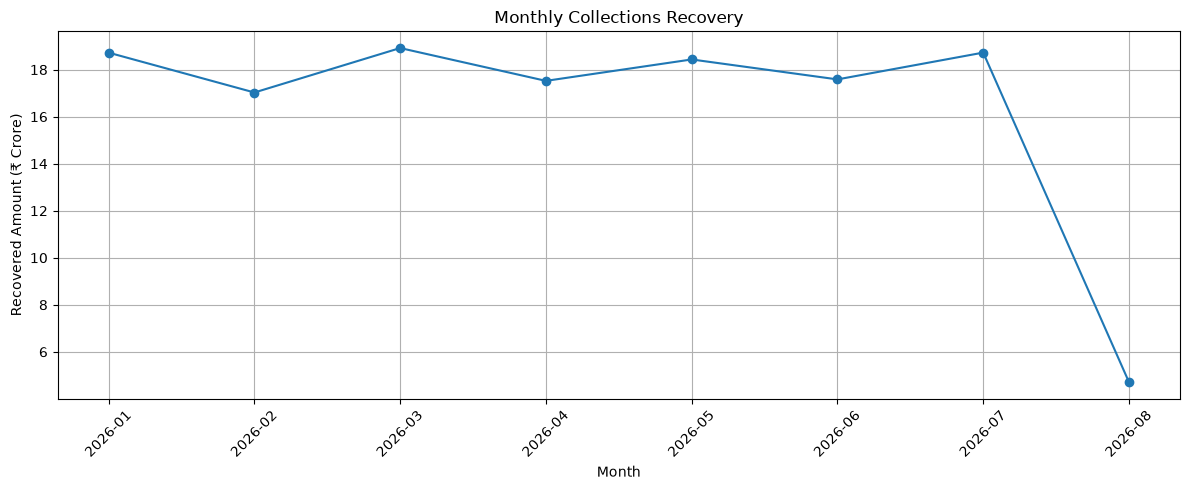

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_recovery_clean["month"].astype(str),
    monthly_recovery_clean["recovered_amount"] / 10000000,
    marker="o"
)

plt.title("Monthly Collections Recovery")
plt.xlabel("Month")
plt.ylabel("Recovered Amount (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
display(
    monthly_recovery_clean[
        ["month", "recovered_amount", "mom_growth_pct"]
    ].round(2)
)

C:\Users\Vani\AppData\Local\Temp\ipykernel_9212\555382717.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,month,recovered_amount,mom_growth_pct
0,2026-01,1.872291e+08,NaN
1,2026-02,1.702796e+08,-9.05
2,2026-03,1.891903e+08,11.11
3,2026-04,1.752289e+08,-7.38
4,2026-05,1.843355e+08,5.20
5,2026-06,1.758534e+08,-4.60
6,2026-07,1.872478e+08,6.48
7,2026-08,4.710970e+07,-74.84


In [19]:
# Load accounts dataset
accounts = pd.read_csv("../data/raw/accounts.csv")

print("ACCOUNTS DATASET")
print("Shape:", accounts.shape)

print("\nColumn names:")
print(accounts.columns.tolist())

print("\nFirst 5 records:")
display(accounts.head())

print("\nDataset information:")
accounts.info()

ACCOUNTS DATASET
Shape: (30000, 11)

Column names:
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

First 5 records:


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,v1
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,v3
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2
3,ACC0000004,BRW0001993,PERSONAL,76435.07,508427.73,30,LOW,CLOSED,2025-05-25 19:29:38,UTC,v2
4,ACC0000005,BRW0009976,CONSUMER,646797.08,563858.01,180,LOW,WRITEOFF,2025-09-07 14:59:13,Asia/Dubai,v2



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   account_id          30000 non-null  str    
 1   borrower_id         29545 non-null  str    
 2   loan_type           30000 non-null  str    
 3   principal_amount    30000 non-null  float64
 4   outstanding_amount  30000 non-null  float64
 5   dpd                 30000 non-null  int64  
 6   risk_segment        30000 non-null  str    
 7   status              30000 non-null  str    
 8   opened_at           30000 non-null  str    
 9   timezone            30000 non-null  str    
 10  schema_version      30000 non-null  str    
dtypes: float64(2), int64(1), str(8)
memory usage: 4.4 MB


In [20]:
# Check missing values
print("MISSING VALUES")
display(accounts.isnull().sum())

# Check duplicate account IDs
print("\nDUPLICATE ACCOUNT IDs")
print(accounts["account_id"].duplicated().sum())

# Check loan types
print("\nLOAN TYPES")
display(accounts["loan_type"].value_counts())

# Check risk segments
print("\nRISK SEGMENTS")
display(accounts["risk_segment"].value_counts())

# Check account statuses
print("\nACCOUNT STATUSES")
display(accounts["status"].value_counts())

# Numerical summary
print("\nACCOUNT AMOUNT SUMMARY")
display(
    accounts[
        ["principal_amount", "outstanding_amount", "dpd"]
    ].describe().round(2)
)

MISSING VALUES


account_id              0
borrower_id           455
loan_type               0
principal_amount        0
outstanding_amount      0
dpd                     0
risk_segment            0
status                  0
opened_at               0
timezone                0
schema_version          0
dtype: int64


DUPLICATE ACCOUNT IDs
0

LOAN TYPES


loan_type
CREDIT_CARD    6080
AUTO           6079
PERSONAL       5983
CONSUMER       5930
BNPL           5928
Name: count, dtype: int64


RISK SEGMENTS


risk_segment
HIGH      7552
MEDIUM    7533
LOW       7513
NPA       7402
Name: count, dtype: int64


ACCOUNT STATUSES


status
ACTIVE      7539
CLOSED      7496
PAID        7486
WRITEOFF    7479
Name: count, dtype: int64


ACCOUNT AMOUNT SUMMARY


,principal_amount,outstanding_amount,dpd
count,30000.00,30000.00,30000.00
mean,403455.52,349634.51,56.51
std,228521.36,201660.39,53.97
min,10055.11,1002.67,0.00
25%,204114.10,175556.82,5.00
50%,403456.50,349587.08,45.00
75%,601484.35,522953.69,90.00
max,799968.38,699963.89,180.00


In [21]:
# Calculate account-level outstanding summary

print("TOTAL PRINCIPAL AMOUNT:")
print(accounts["principal_amount"].sum())

print("\nTOTAL OUTSTANDING AMOUNT:")
print(accounts["outstanding_amount"].sum())

print("\nAVERAGE OUTSTANDING AMOUNT:")
print(accounts["outstanding_amount"].mean())

print("\nAVERAGE DAYS PAST DUE:")
print(accounts["dpd"].mean())

TOTAL PRINCIPAL AMOUNT:
12103665653.54

TOTAL OUTSTANDING AMOUNT:
10489035343.0

AVERAGE OUTSTANDING AMOUNT:
349634.51143333333

AVERAGE DAYS PAST DUE:
56.506433333333334


In [22]:
# Outstanding amount by risk segment

risk_analysis = (
    accounts.groupby("risk_segment")
    .agg(
        total_accounts=("account_id", "count"),
        total_outstanding=("outstanding_amount", "sum"),
        average_outstanding=("outstanding_amount", "mean"),
        average_dpd=("dpd", "mean")
    )
    .reset_index()
)

display(risk_analysis.round(2))

,risk_segment,total_accounts,total_outstanding,average_outstanding,average_dpd
0,HIGH,7552,2.646183e+09,350394.94,56.45
1,LOW,7513,2.633311e+09,350500.61,57.97
2,MEDIUM,7533,2.628179e+09,348888.82,54.76
3,NPA,7402,2.581362e+09,348738.48,56.85


In [23]:
# Outstanding amount by loan type

loan_analysis = (
    accounts.groupby("loan_type")
    .agg(
        total_accounts=("account_id", "count"),
        total_outstanding=("outstanding_amount", "sum"),
        average_outstanding=("outstanding_amount", "mean"),
        average_dpd=("dpd", "mean")
    )
    .reset_index()
    .sort_values("total_outstanding", ascending=False)
)

display(loan_analysis.round(2))

,loan_type,total_accounts,total_outstanding,average_outstanding,average_dpd
0,AUTO,6079,2.135301e+09,351258.57,56.45
3,CREDIT_CARD,6080,2.126677e+09,349782.39,56.73
4,PERSONAL,5983,2.095030e+09,350163.84,56.35
2,CONSUMER,5930,2.073113e+09,349597.42,56.61
1,BNPL,5928,2.058915e+09,347320.28,56.38


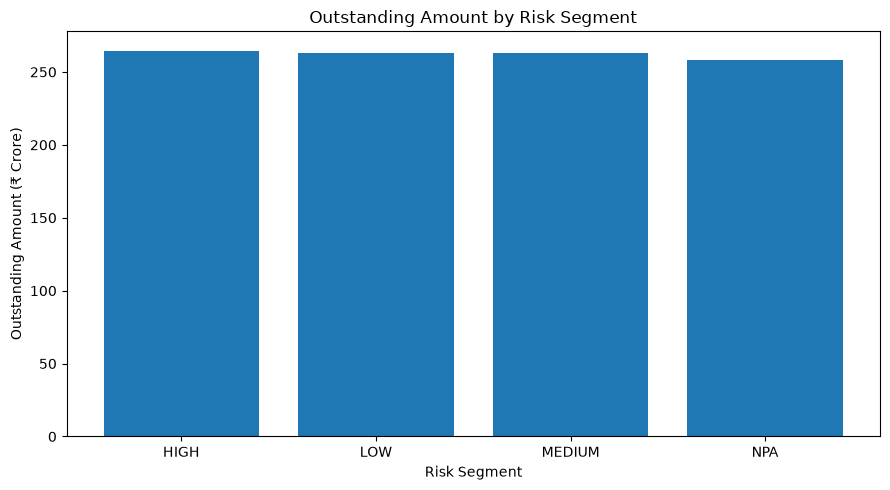

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    risk_analysis["risk_segment"],
    risk_analysis["total_outstanding"] / 10000000
)

plt.title("Outstanding Amount by Risk Segment")
plt.xlabel("Risk Segment")
plt.ylabel("Outstanding Amount (₹ Crore)")
plt.tight_layout()

plt.savefig(
    "../reports/outstanding_by_risk.png",
    dpi=300
)

plt.show()

In [25]:
# Remove exact duplicate payment rows in a separate copy
payments_for_join = payment_analysis.drop_duplicates().copy()

# Aggregate successful payments by account
account_payments = (
    payments_for_join[
        payments_for_join["payment_status"] == "SUCCESS"
    ]
    .groupby("account_id")
    .agg(
        successful_payment_amount=("amount", "sum"),
        successful_payment_count=("payment_id", "count")
    )
    .reset_index()
)

# Join accounts with payment summaries
account_recovery = accounts.merge(
    account_payments,
    on="account_id",
    how="left"
)

# Fill accounts without successful payments
account_recovery["successful_payment_amount"] = (
    account_recovery["successful_payment_amount"].fillna(0)
)

account_recovery["successful_payment_count"] = (
    account_recovery["successful_payment_count"].fillna(0)
)

print("Merged dataset shape:", account_recovery.shape)

display(account_recovery.head())

Merged dataset shape: (30000, 13)


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version,successful_payment_amount,successful_payment_count
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,v1,114222.84,1.0
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,v3,0.00,0.0
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2,118181.69,2.0
3,ACC0000004,BRW0001993,PERSONAL,76435.07,508427.73,30,LOW,CLOSED,2025-05-25 19:29:38,UTC,v2,120763.00,1.0
4,ACC0000005,BRW0009976,CONSUMER,646797.08,563858.01,180,LOW,WRITEOFF,2025-09-07 14:59:13,Asia/Dubai,v2,0.00,0.0


In [26]:
risk_recovery = (
    account_recovery
    .groupby("risk_segment")
    .agg(
        total_accounts=("account_id", "count"),
        outstanding_amount=("outstanding_amount", "sum"),
        successful_payment_amount=(
            "successful_payment_amount", "sum"
        )
    )
    .reset_index()
)

display(risk_recovery.round(2))

,risk_segment,total_accounts,outstanding_amount,successful_payment_amount
0,HIGH,7552,2.646183e+09,3.317907e+08
1,LOW,7513,2.633311e+09,3.311408e+08
2,MEDIUM,7533,2.628179e+09,3.309252e+08
3,NPA,7402,2.581362e+09,3.226178e+08


In [27]:
# Investigate NPA payment records

npa_data = account_recovery[
    account_recovery["risk_segment"] == "NPA"
]

print("NPA account count:", len(npa_data))

print(
    "Missing successful payment amounts:",
    npa_data["successful_payment_amount"].isnull().sum()
)

print(
    "NPA accounts with successful payments:",
    (npa_data["successful_payment_amount"] > 0).sum()
)

print(
    "Total NPA successful payment amount:",
    npa_data["successful_payment_amount"].sum()
)

display(npa_data.head(10))

NPA account count: 7402
Missing successful payment amounts: 0
NPA accounts with successful payments: 3268
Total NPA successful payment amount: 322617813.40999997


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version,successful_payment_amount,successful_payment_count
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2,118181.69,2.0
8,ACC0000009,BRW0009929,AUTO,468473.94,546432.13,0,NPA,PAID,2024-07-03 01:36:33,UTC,v2,0.00,0.0
9,ACC0000010,BRW0010210,CREDIT_CARD,503912.27,480229.21,120,NPA,ACTIVE,2025-03-18 02:20:35,Asia/Dubai,v1,113781.45,1.0
10,ACC0000011,BRW0008297,CONSUMER,664562.90,443718.00,180,NPA,ACTIVE,2025-06-08 19:02:58,UTC,v1,98816.74,1.0
14,ACC0000015,NaN,CREDIT_CARD,458992.65,571588.51,180,NPA,PAID,2024-01-17 21:15:07,Asia/Kolkata,v1,43465.37,1.0
16,ACC0000017,BRW0011295,BNPL,534698.26,5858.33,180,NPA,ACTIVE,2024-08-28 03:16:58,Asia/Kolkata,v1,0.00,0.0
19,ACC0000020,BRW0009853,PERSONAL,161866.22,45094.95,45,NPA,WRITEOFF,2024-09-06 11:46:18,Asia/Kolkata,v1,0.00,0.0
28,ACC0000029,BRW0004858,CREDIT_CARD,543313.14,397975.88,60,NPA,PAID,2025-06-21 06:57:45,Asia/Dubai,v3,54002.91,1.0
33,ACC0000034,BRW0005128,AUTO,418210.77,477990.41,15,NPA,CLOSED,2024-04-13 15:54:59,Asia/Dubai,v2,0.00,0.0
35,ACC0000036,BRW0008512,CREDIT_CARD,203070.58,43455.51,30,NPA,PAID,2024-09-04 02:04:25,Asia/Kolkata,v2,0.00,0.0


In [28]:
# Risk-wise recovery summary

risk_summary = (
    account_recovery
    .groupby("risk_segment")
    .agg(
        accounts=("account_id", "count"),
        outstanding=("outstanding_amount", "sum"),
        recovered=("successful_payment_amount", "sum")
    )
    .reset_index()
)

risk_summary["recovery_to_outstanding_pct"] = (
    risk_summary["recovered"] /
    risk_summary["outstanding"] * 100
)

display(risk_summary.round(2))

,risk_segment,accounts,outstanding,recovered,recovery_to_outstanding_pct
0,HIGH,7552,2.646183e+09,3.317907e+08,12.54
1,LOW,7513,2.633311e+09,3.311408e+08,12.58
2,MEDIUM,7533,2.628179e+09,3.309252e+08,12.59
3,NPA,7402,2.581362e+09,3.226178e+08,12.50


In [29]:
borrowers = pd.read_csv("../data/raw/borrowers.csv")

print("BORROWERS DATASET SHAPE:", borrowers.shape)

print("\nCOLUMN NAMES:")
print(borrowers.columns.tolist())

print("\nFIRST FIVE RECORDS:")
display(borrowers.head())

print("\nDATASET INFORMATION:")
borrowers.info()

BORROWERS DATASET SHAPE: (30600, 8)

COLUMN NAMES:
['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']

FIRST FIVE RECORDS:


,borrower_id,name,phone,email,city,created_at,updated_at,state
0,BRW0001072,Rahul Verma,9.037419e+09,user9183@example.com,Bhubaneswar,2025-09-25 08:02:29,2026-07-25 22:25:48,Odisha
1,BRW0009288,Neha Singh,9.154913e+09,user9581@example.com,Gurugram,2025-06-29 04:32:01,2025-03-04 12:15:30,Haryana
2,BRW0007855,Vikram Shah,9.986755e+09,user19407@example.com,Hyderabad,2025-11-23 20:30:50,2025-01-07 21:07:17,Telangana
3,BRW0005267,Priya Mehta,9.145160e+09,user4619@example.com,Jaipur,2026-05-09 11:34:12,2025-04-24 21:35:48,Rajasthan
4,BRW0005197,Priya Mehta,9.655567e+09,user4597@example.com,Mumbai,2025-02-13 03:53:20,2026-03-29 19:42:02,Maharashtra



DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 30600 entries, 0 to 30599
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   borrower_id  30600 non-null  str    
 1   name         30600 non-null  str    
 2   phone        29986 non-null  float64
 3   email        29705 non-null  str    
 4   city         30600 non-null  str    
 5   created_at   30600 non-null  str    
 6   updated_at   30600 non-null  str    
 7   state        30600 non-null  str    
dtypes: float64(1), str(7)
memory usage: 4.6 MB


In [30]:
# Borrower distribution by state

state_analysis = (
    borrowers.groupby("state")
    .size()
    .reset_index(name="borrower_count")
    .sort_values("borrower_count", ascending=False)
)

print("TOP 10 STATES")
display(state_analysis.head(10))

# Borrower distribution by city

city_analysis = (
    borrowers.groupby("city")
    .size()
    .reset_index(name="borrower_count")
    .sort_values("borrower_count", ascending=False)
)

print("\nTOP 10 CITIES")
display(city_analysis.head(10))

TOP 10 STATES


,state,borrower_count
3,Maharashtra,6092
0,Delhi,3171
7,Telangana,3119
4,Odisha,3094
2,Karnataka,3074
6,Tamil Nadu,3073
1,Haryana,3054
5,Rajasthan,3003
8,West Bengal,2920



TOP 10 CITIES


,city,borrower_count
3,Delhi,3171
5,Hyderabad,3119
1,Bhubaneswar,3094
9,Pune,3090
0,Bengaluru,3074
2,Chennai,3073
4,Gurugram,3054
6,Jaipur,3003
8,Mumbai,3002
7,Kolkata,2920


In [31]:
print("Total borrowers:", len(borrowers))

print(
    "Duplicate borrower IDs:",
    borrowers["borrower_id"].duplicated().sum()
)

print("\nMissing values:")
display(borrowers.isnull().sum())

print("\nUnique states:", borrowers["state"].nunique())
print("Unique cities:", borrowers["city"].nunique())

Total borrowers: 30600
Duplicate borrower IDs: 19585

Missing values:


borrower_id      0
name             0
phone          614
email          895
city             0
created_at       0
updated_at       0
state            0
dtype: int64


Unique states: 9
Unique cities: 10


In [32]:
# Investigate duplicate borrower IDs

duplicate_borrowers = borrowers[
    borrowers.duplicated("borrower_id", keep=False)
].copy()

print("Total duplicate records:",
      len(duplicate_borrowers))

print("Unique repeated borrower IDs:",
      duplicate_borrowers["borrower_id"].nunique())

# Check whether duplicate records are identical

duplicate_groups = (
    duplicate_borrowers
    .groupby("borrower_id")
    .apply(
        lambda group: group.drop(
            columns=["borrower_id"]
        ).nunique(dropna=False).max() == 1
    )
)

print("Identical borrower groups:",
      duplicate_groups.sum())

print("Conflicting borrower groups:",
      (~duplicate_groups).sum())

# Display sample duplicate records

display(
    duplicate_borrowers.sort_values("borrower_id").head(15)
)

Total duplicate records: 28151
Unique repeated borrower IDs: 8566


KeyError: "['borrower_id'] not found in axis"

In [33]:
# Investigate duplicate borrower IDs

duplicate_borrowers = borrowers[
    borrowers.duplicated("borrower_id", keep=False)
].copy()

print("Total duplicate records:",
      len(duplicate_borrowers))

print("Unique repeated borrower IDs:",
      duplicate_borrowers["borrower_id"].nunique())


# Compare all columns except borrower_id

comparison_columns = [
    col for col in duplicate_borrowers.columns
    if col != "borrower_id"
]

duplicate_groups = (
    duplicate_borrowers
    .groupby("borrower_id")[comparison_columns]
    .nunique(dropna=False)
    .max(axis=1)
    .eq(1)
)

print("\nIdentical borrower groups:",
      duplicate_groups.sum())

print("Conflicting borrower groups:",
      (~duplicate_groups).sum())


# Display sample duplicate records

display(
    duplicate_borrowers
    .sort_values("borrower_id")
    .head(15)
)

Total duplicate records: 28151
Unique repeated borrower IDs: 8566

Identical borrower groups: 48
Conflicting borrower groups: 8518


,borrower_id,name,phone,email,city,created_at,updated_at,state
5082,BRW0000001,Aarav Sharma,9.962893e+09,user8164@example.com,Kolkata,2025-11-04 23:36:22,2026-06-22 12:05:30,West Bengal
20435,BRW0000001,Rohan Patel,9.712907e+09,user4799@example.com,Hyderabad,2026-07-17 04:33:13,2025-11-22 01:34:14,Telangana
27686,BRW0000001,Aarav Sharma,9.237818e+09,user10670@example.com,Hyderabad,2025-12-03 00:18:45,2026-06-25 02:44:50,Telangana
10963,BRW0000004,Neha Singh,9.714461e+09,user18767@example.com,Bengaluru,2025-07-03 17:14:49,2025-01-15 08:16:46,Karnataka
20050,BRW0000004,Vikram Shah,9.072501e+09,user13710@example.com,Gurugram,2025-11-16 08:32:03,2025-10-31 11:10:43,Haryana
23818,BRW0000004,Ananya Rao,9.076787e+09,user15119@example.com,Delhi,2025-07-20 23:45:10,2025-12-20 18:43:35,Delhi
29546,BRW0000004,Pooja Nair,9.936985e+09,user11254@example.com,Mumbai,2026-02-10 12:40:50,2025-12-16 20:36:28,Maharashtra
8282,BRW0000005,Sneha Das,9.359023e+09,user5979@example.com,Pune,2026-03-18 14:01:59,2025-07-07 09:59:12,Maharashtra
18692,BRW0000005,Neha Singh,9.269813e+09,user4520@example.com,Mumbai,2026-02-07 14:08:27,2025-12-04 08:52:09,Maharashtra
30325,BRW0000005,Neha Singh,9.269813e+09,user4520@example.com,Mumbai,2026-02-07 14:08:27,2025-12-04 08:52:09,Maharashtra


In [34]:
# Frequency of repeated borrower IDs

borrower_frequency = (
    borrowers.groupby("borrower_id")
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

print("Borrower ID frequency distribution:")

display(
    borrower_frequency["record_count"]
    .value_counts()
    .sort_index()
)

print("\nTop 10 repeated borrower IDs:")

display(borrower_frequency.head(10))

Borrower ID frequency distribution:


record_count
1     2449
2     3023
3     2449
4     1645
5      840
6      395
7      134
8       57
9       18
10       3
11       2
Name: count, dtype: int64


Top 10 repeated borrower IDs:


,borrower_id,record_count
5812,BRW0006302,11
8150,BRW0008879,11
4966,BRW0005385,10
2327,BRW0002520,10
1153,BRW0001237,10
3796,BRW0004112,9
10144,BRW0011052,9
9241,BRW0010060,9
3731,BRW0004044,9
6461,BRW0007009,9


In [35]:
# Check borrower IDs in account dataset

accounts = pd.read_csv("../data/raw/accounts.csv")

print("Total account records:", len(accounts))

print(
    "Unique borrower IDs in accounts:",
    accounts["borrower_id"].nunique()
)

print(
    "Missing borrower IDs in accounts:",
    accounts["borrower_id"].isnull().sum()
)

print(
    "Borrower IDs appearing in both datasets:",
    accounts["borrower_id"].isin(
        borrowers["borrower_id"]
    ).sum()
)

Total account records: 30000
Unique borrower IDs in accounts: 10943
Missing borrower IDs in accounts: 455
Borrower IDs appearing in both datasets: 27087


In [36]:
# Account and loan analysis

print("LOAN TYPE DISTRIBUTION")

loan_analysis = (
    accounts.groupby("loan_type")
    .agg(
        total_accounts=("account_id", "count"),
        outstanding_amount=("outstanding_amount", "sum"),
        principal_amount=("principal_amount", "sum")
    )
    .reset_index()
)

display(loan_analysis.round(2))


print("\nACCOUNT STATUS DISTRIBUTION")

status_analysis = (
    accounts.groupby("status")
    .agg(
        total_accounts=("account_id", "count"),
        outstanding_amount=("outstanding_amount", "sum")
    )
    .reset_index()
)

display(status_analysis.round(2))


print("\nOVERDUE ACCOUNT ANALYSIS")

accounts["dpd_category"] = pd.cut(
    accounts["dpd"],
    bins=[-1, 0, 30, 60, 90, float("inf")],
    labels=["Current", "1-30 Days", "31-60 Days",
            "61-90 Days", "90+ Days"]
)

dpd_analysis = (
    accounts.groupby("dpd_category", observed=False)
    .agg(
        account_count=("account_id", "count"),
        outstanding_amount=("outstanding_amount", "sum")
    )
    .reset_index()
)

display(dpd_analysis.round(2))

LOAN TYPE DISTRIBUTION


,loan_type,total_accounts,outstanding_amount,principal_amount
0,AUTO,6079,2.135301e+09,2.440528e+09
1,BNPL,5928,2.058915e+09,2.389513e+09
2,CONSUMER,5930,2.073113e+09,2.387306e+09
3,CREDIT_CARD,6080,2.126677e+09,2.451801e+09
4,PERSONAL,5983,2.095030e+09,2.434517e+09



ACCOUNT STATUS DISTRIBUTION


,status,total_accounts,outstanding_amount
0,ACTIVE,7539,2.637397e+09
1,CLOSED,7496,2.636143e+09
2,PAID,7486,2.617540e+09
3,WRITEOFF,7479,2.597956e+09



OVERDUE ACCOUNT ANALYSIS


,dpd_category,account_count,outstanding_amount
0,Current,2685,9.482186e+08
1,1-30 Days,10880,3.834101e+09
2,31-60 Days,5514,1.914490e+09
3,61-90 Days,5468,1.895868e+09
4,90+ Days,5453,1.896357e+09


In [37]:
# Agent dataset inspection

agents = pd.read_csv("../data/raw/agents.csv")
calls = pd.read_csv("../data/raw/calls.csv")

print("AGENTS DATASET")
print("Shape:", agents.shape)
print("Columns:", agents.columns.tolist())
display(agents.head())

print("\nCALLS DATASET")
print("Shape:", calls.shape)
print("Columns:", calls.columns.tolist())
display(calls.head())

print("\nCALL DATA INFORMATION")
calls.info()

AGENTS DATASET
Shape: (30000, 8)
Columns: ['agent_id', 'employee_code', 'agent_name', 'vendor_id', 'team', 'status', 'joined_at', 'updated_at']


,agent_id,employee_code,agent_name,vendor_id,team,status,joined_at,updated_at
0,AGT0000760,EMP00323,Vikram Shah,VND0000012,T3,INACTIVE,2025-06-19 20:30:53,2025-12-11 03:40:22
1,AGT0000171,EMP00079,Pooja Nair,VND0000012,T1,INACTIVE,2025-08-26 11:06:26,2025-10-11 08:30:33
2,AGT0000766,EMP00030,Sneha Das,VND0000002,FIELD,SUSPENDED,2024-05-30 11:23:06,2026-05-16 03:02:02
3,AGT0000031,EMP00334,Aarav Sharma,VND0000007,T1,INACTIVE,2024-10-11 18:58:28,2025-10-16 13:31:21
4,AGT0000669,EMP00014,Aarav Sharma,VND0000001,T3,SUSPENDED,2024-09-01 19:55:06,2026-07-04 03:33:11



CALLS DATASET
Shape: (91350, 11)
Columns: ['call_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'campaign_id', 'direction', 'vendor_id', 'call_status', 'duration_sec', 'timezone']


,call_id,account_id,borrower_id,event_at,agent_id,campaign_id,direction,vendor_id,call_status,duration_sec,timezone
0,CALL0000001,ACC0011505,BRW0007139,2026-07-15 15:36:22,AGT0000955,CMP0000015,OUTBOUND,VND0000013,NO_ANSWER,601,Asia/Dubai
1,CALL0000002,ACC0002025,BRW0006253,2026-06-10 06:48:27,AGT0000853,CMP0000060,OUTBOUND,VND0000001,ANSWERED,224,Asia/Kolkata
2,CALL0000003,ACC0013375,BRW0007663,2026-04-07 00:35:35,AGT0000525,CMP0000060,OUTBOUND,VND0000008,FAILED,7,Asia/Dubai
3,CALL0000004,ACC0021534,BRW0008873,2026-02-12 14:16:57,AGT0000945,CMP0000060,OUTBOUND,VND0000001,VOICEMAIL,896,Asia/Dubai
4,CALL0000005,ACC0018502,BRW0004996,2026-05-24 15:33:12,AGT0000966,CMP0000053,OUTBOUND,VND0000006,ANSWERED,711,Asia/Kolkata



CALL DATA INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 91350 entries, 0 to 91349
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   call_id       91350 non-null  str  
 1   account_id    91350 non-null  str  
 2   borrower_id   91350 non-null  str  
 3   event_at      91350 non-null  str  
 4   agent_id      89523 non-null  str  
 5   campaign_id   91350 non-null  str  
 6   direction     91350 non-null  str  
 7   vendor_id     91350 non-null  str  
 8   call_status   91350 non-null  str  
 9   duration_sec  91350 non-null  int64
 10  timezone      91350 non-null  str  
dtypes: int64(1), str(10)
memory usage: 16.7 MB


In [38]:
# Call performance analysis

print("TOTAL CALLS:", len(calls))

print("\nCALL STATUS DISTRIBUTION")
display(calls["call_status"].value_counts())

print("\nCALL DIRECTION")
display(calls["direction"].value_counts())

print("\nAGENT CALL PERFORMANCE")

agent_performance = (
    calls.groupby("agent_id")
    .agg(
        total_calls=("call_id", "count"),
        average_duration=("duration_sec", "mean"),
        total_duration=("duration_sec", "sum"),
        unique_accounts=("account_id", "nunique")
    )
    .reset_index()
    .sort_values("total_calls", ascending=False)
)

display(agent_performance.head(10).round(2))

print("\nMISSING AGENT IDs:",
      calls["agent_id"].isnull().sum())

TOTAL CALLS: 91350

CALL STATUS DISTRIBUTION


call_status
NO_ANSWER    18363
BUSY         18330
FAILED       18276
VOICEMAIL    18235
ANSWERED     18146
Name: count, dtype: int64


CALL DIRECTION


direction
OUTBOUND    84151
INBOUND      7199
Name: count, dtype: int64


AGENT CALL PERFORMANCE


,agent_id,total_calls,average_duration,total_duration,unique_accounts
122,AGT0000123,131,453.88,59458,129
992,AGT0000993,119,463.06,55104,117
550,AGT0000551,119,409.45,48724,115
274,AGT0000275,119,437.84,52103,117
344,AGT0000345,118,401.65,47395,116
781,AGT0000782,117,472.97,55338,114
298,AGT0000299,117,450.99,52766,111
221,AGT0000222,115,454.53,52271,111
194,AGT0000195,115,478.26,55000,114
959,AGT0000960,114,403.43,45991,113



MISSING AGENT IDs: 1827


In [39]:
print("AGENT DATASET SHAPE:", agents.shape)

print("\nAGENT COLUMNS:")
print(agents.columns.tolist())

display(agents.head(10))

AGENT DATASET SHAPE: (30000, 8)

AGENT COLUMNS:
['agent_id', 'employee_code', 'agent_name', 'vendor_id', 'team', 'status', 'joined_at', 'updated_at']


,agent_id,employee_code,agent_name,vendor_id,team,status,joined_at,updated_at
0,AGT0000760,EMP00323,Vikram Shah,VND0000012,T3,INACTIVE,2025-06-19 20:30:53,2025-12-11 03:40:22
1,AGT0000171,EMP00079,Pooja Nair,VND0000012,T1,INACTIVE,2025-08-26 11:06:26,2025-10-11 08:30:33
2,AGT0000766,EMP00030,Sneha Das,VND0000002,FIELD,SUSPENDED,2024-05-30 11:23:06,2026-05-16 03:02:02
3,AGT0000031,EMP00334,Aarav Sharma,VND0000007,T1,INACTIVE,2024-10-11 18:58:28,2025-10-16 13:31:21
4,AGT0000669,EMP00014,Aarav Sharma,VND0000001,T3,SUSPENDED,2024-09-01 19:55:06,2026-07-04 03:33:11
5,AGT0000968,EMP00060,Amit Kumar,VND0000012,T1,ACTIVE,2025-04-30 13:05:13,2025-02-11 19:01:45
6,AGT0000155,EMP00636,Amit Kumar,VND0000007,DIGITAL,SUSPENDED,2024-12-07 13:58:39,2026-07-28 06:16:07
7,AGT0000480,EMP00420,Aarav Sharma,VND0000005,FIELD,INACTIVE,2024-02-16 22:56:23,2025-02-01 18:17:09
8,AGT0000404,EMP00148,Rahul Verma,VND0000009,DIGITAL,INACTIVE,2024-04-02 12:16:02,2025-10-13 14:12:16
9,AGT0000077,EMP00415,Aarav Sharma,VND0000003,T2,ACTIVE,2025-07-29 21:47:05,2026-05-28 01:38:51


In [40]:
# Agent-wise performance analysis

agent_summary = (
    calls.dropna(subset=["agent_id"])
    .groupby("agent_id")
    .agg(
        total_calls=("call_id", "count"),
        answered_calls=(
            "call_status",
            lambda x: (x == "ANSWERED").sum()
        ),
        average_duration=("duration_sec", "mean"),
        unique_accounts=("account_id", "nunique")
    )
    .reset_index()
)

# Calculate answer rate

agent_summary["answer_rate_pct"] = (
    agent_summary["answered_calls"] /
    agent_summary["total_calls"] * 100
)

# Attach agent details

agent_details = agents[
    ["agent_id", "agent_name", "team", "status"]
].drop_duplicates("agent_id")

agent_summary = agent_summary.merge(
    agent_details,
    on="agent_id",
    how="left"
)

# Top 10 agents

top_agents = agent_summary.sort_values(
    "total_calls", ascending=False
).head(10)

print("TOP 10 AGENTS BY CALL VOLUME")

display(top_agents.round(2))

print("\nTOTAL AGENTS WITH CALL RECORDS:",
      agent_summary["agent_id"].nunique())

print("\nAGENTS WITHOUT MATCHING DETAILS:",
      agent_summary["agent_name"].isnull().sum())

TOP 10 AGENTS BY CALL VOLUME


,agent_id,total_calls,answered_calls,average_duration,unique_accounts,answer_rate_pct,agent_name,team,status
122,AGT0000123,131,19,453.88,129,14.50,Rohan Patel,T1,INACTIVE
992,AGT0000993,119,14,463.06,117,11.76,Sneha Das,T1,ACTIVE
550,AGT0000551,119,29,409.45,115,24.37,Vikram Shah,T3,INACTIVE
274,AGT0000275,119,23,437.84,117,19.33,Aarav Sharma,T1,INACTIVE
344,AGT0000345,118,31,401.65,116,26.27,Aarav Sharma,T1,SUSPENDED
781,AGT0000782,117,26,472.97,114,22.22,Pooja Nair,T3,INACTIVE
298,AGT0000299,117,20,450.99,111,17.09,Ananya Rao,T3,INACTIVE
221,AGT0000222,115,21,454.53,111,18.26,Priya Mehta,T1,ACTIVE
194,AGT0000195,115,27,478.26,114,23.48,Priya Mehta,FIELD,ACTIVE
959,AGT0000960,114,19,403.43,113,16.67,Vikram Shah,T2,INACTIVE



TOTAL AGENTS WITH CALL RECORDS: 1000

AGENTS WITHOUT MATCHING DETAILS: 0


In [41]:
# Campaign performance analysis

campaign_analysis = (
    calls.groupby("campaign_id")
    .agg(
        total_calls=("call_id", "count"),
        answered_calls=(
            "call_status",
            lambda x: (x == "ANSWERED").sum()
        ),
        unique_borrowers=("borrower_id", "nunique"),
        average_duration=("duration_sec", "mean")
    )
    .reset_index()
)

campaign_analysis["answer_rate_pct"] = (
    campaign_analysis["answered_calls"] /
    campaign_analysis["total_calls"] * 100
)

campaign_analysis = campaign_analysis.sort_values(
    "total_calls", ascending=False
)

print("TOP 10 CAMPAIGNS")

display(campaign_analysis.head(10).round(2))

print("\nTOTAL CAMPAIGNS:",
      campaign_analysis["campaign_id"].nunique())

TOP 10 CAMPAIGNS


,campaign_id,total_calls,answered_calls,unique_borrowers,average_duration,answer_rate_pct
113,CMP0000114,835,166,797,445.14,19.88
91,CMP0000092,825,162,779,456.91,19.64
115,CMP0000116,825,166,788,451.41,20.12
78,CMP0000079,814,169,780,439.92,20.76
59,CMP0000060,810,149,771,442.42,18.40
99,CMP0000100,808,149,762,442.97,18.44
35,CMP0000036,806,176,765,456.60,21.84
57,CMP0000058,802,173,755,457.68,21.57
102,CMP0000103,802,134,768,447.93,16.71
13,CMP0000014,798,152,764,434.04,19.05



TOTAL CAMPAIGNS: 120


In [42]:
campaigns = pd.read_csv("../data/raw/campaigns.csv")

print("CAMPAIGN DATASET SHAPE:", campaigns.shape)

print("\nCAMPAIGN COLUMNS:")
print(campaigns.columns.tolist())

display(campaigns.head(10))

CAMPAIGN DATASET SHAPE: (120, 7)

CAMPAIGN COLUMNS:
['campaign_id', 'campaign_name', 'channel', 'strategy_version', 'start_at', 'target_definition', 'end_at']


,campaign_id,campaign_name,channel,strategy_version,start_at,target_definition,end_at
0,CMP0000001,DIGITAL_FOLLOWUP,FIELD,legacy,2026-02-17 06:56:01,DPD>=30,2026-04-24 06:56:01
1,CMP0000002,BOUNCE,MIXED,v2,2026-04-30 17:51:31,DPD>=60,2026-05-18 17:51:31
2,CMP0000003,30DPD_W1,MIXED,v1,2026-04-11 16:02:51,DPD>=30,2026-05-18 16:02:51
3,CMP0000004,BOUNCE,VOICE,legacy,2026-04-28 06:15:30,DPD>=60,2026-05-29 06:15:30
4,CMP0000005,60DPD_INTENT,WHATSAPP,legacy,2026-05-04 04:16:21,DPD>=60,2026-07-08 04:16:21
5,CMP0000006,BOUNCE,MIXED,legacy,2026-01-23 09:30:10,DPD>=60,2026-04-13 09:30:10
6,CMP0000007,DIGITAL_FOLLOWUP,MIXED,v2,2026-02-14 15:20:05,PROMISE_BROKEN,2026-04-22 15:20:05
7,CMP0000008,NPA_RECOVERY,SMS,v2,2026-05-21 10:58:25,PROMISE_BROKEN,2026-06-27 10:58:25
8,CMP0000009,60DPD_INTENT,WHATSAPP,v1,2026-04-18 15:47:29,HIGH_RISK,2026-06-07 15:47:29
9,CMP0000010,30DPD_W1,FIELD,v1,2026-02-14 13:09:24,DPD>=30,2026-04-30 13:09:24


In [43]:
# Merge campaign performance with campaign details

campaign_performance = campaign_analysis.merge(
    campaigns,
    on="campaign_id",
    how="left"
)

print("CAMPAIGN PERFORMANCE SHAPE:",
      campaign_performance.shape)

print("\nTOP 10 CAMPAIGNS WITH DETAILS")

display(
    campaign_performance
    .sort_values("answer_rate_pct", ascending=False)
    .head(10)
    [[
        "campaign_id",
        "campaign_name",
        "channel",
        "strategy_version",
        "total_calls",
        "answered_calls",
        "answer_rate_pct"
    ]]
    .round(2)
)

CAMPAIGN PERFORMANCE SHAPE: (120, 12)

TOP 10 CAMPAIGNS WITH DETAILS


,campaign_id,campaign_name,channel,strategy_version,total_calls,answered_calls,answer_rate_pct
24,CMP0000065,30DPD_W1,WHATSAPP,v3,782,176,22.51
97,CMP0000010,30DPD_W1,FIELD,v1,740,166,22.43
93,CMP0000003,30DPD_W1,MIXED,v1,743,166,22.34
105,CMP0000020,NPA_RECOVERY,WHATSAPP,v3,733,163,22.24
98,CMP0000087,60DPD_INTENT,SMS,legacy,739,164,22.19
111,CMP0000032,NPA_RECOVERY,MIXED,v2,723,160,22.13
80,CMP0000075,30DPD_W1,WHATSAPP,v3,748,165,22.06
33,CMP0000064,60DPD_INTENT,FIELD,v2,775,170,21.94
83,CMP0000009,60DPD_INTENT,WHATSAPP,v1,746,163,21.85
6,CMP0000036,30DPD_W1,SMS,v1,806,176,21.84


In [44]:
# Check missing values in campaign performance

print("MISSING VALUES:")
display(campaign_performance.isnull().sum())

print("\nCAMPAIGNS WITH MISSING PERFORMANCE:")
display(
    campaign_performance[
        campaign_performance["answer_rate_pct"].isnull()
    ]
)


MISSING VALUES:


campaign_id          0
total_calls          0
answered_calls       0
unique_borrowers     0
average_duration     0
answer_rate_pct      0
campaign_name        0
channel              0
strategy_version     0
start_at             0
target_definition    0
end_at               0
dtype: int64


CAMPAIGNS WITH MISSING PERFORMANCE:


,campaign_id,total_calls,answered_calls,unique_borrowers,average_duration,answer_rate_pct,campaign_name,channel,strategy_version,start_at,target_definition,end_at


In [45]:
print("Total campaign records:", len(campaign_performance))

print(
    "Duplicate campaign IDs:",
    campaign_performance["campaign_id"].duplicated().sum()
)

print(
    "Unique campaign IDs:",
    campaign_performance["campaign_id"].nunique()
)

Total campaign records: 120
Duplicate campaign IDs: 0
Unique campaign IDs: 120


In [46]:
# Campaign channel performance analysis

channel_analysis = (
    campaign_performance
    .groupby("channel")
    .agg(
        total_campaigns=("campaign_id", "nunique"),
        total_calls=("total_calls", "sum"),
        answered_calls=("answered_calls", "sum"),
        unique_borrowers=("unique_borrowers", "sum")
    )
    .reset_index()
)

channel_analysis["answer_rate_pct"] = (
    channel_analysis["answered_calls"] /
    channel_analysis["total_calls"] * 100
)

channel_analysis = channel_analysis.sort_values(
    "answer_rate_pct",
    ascending=False
)

print("CAMPAIGN CHANNEL PERFORMANCE")

display(channel_analysis.round(2))

CAMPAIGN CHANNEL PERFORMANCE


,channel,total_campaigns,total_calls,answered_calls,unique_borrowers,answer_rate_pct
1,MIXED,23,17326,3490,16551,20.14
4,WHATSAPP,31,23735,4763,22730,20.07
2,SMS,28,21368,4240,20394,19.84
0,FIELD,18,13639,2704,13003,19.83
3,VOICE,20,15282,2949,14534,19.30


In [47]:
# Call outcome analysis

call_outcomes = (
    calls.groupby("call_status")
    .agg(
        total_calls=("call_id", "count"),
        average_duration=("duration_sec", "mean"),
        unique_borrowers=("borrower_id", "nunique")
    )
    .reset_index()
    .sort_values("total_calls", ascending=False)
)

call_outcomes["call_percentage"] = (
    call_outcomes["total_calls"] / len(calls) * 100
)

display(call_outcomes.round(2))

,call_status,total_calls,average_duration,unique_borrowers,call_percentage
3,NO_ANSWER,18363,448.64,9304,20.10
1,BUSY,18330,451.36,9290,20.07
2,FAILED,18276,451.08,9287,20.01
4,VOICEMAIL,18235,451.82,9234,19.96
0,ANSWERED,18146,452.93,9275,19.86


In [48]:
# Overall project metrics

print("CREDRESOLVE COLLECTIONS ANALYTICS")
print("---------------------------------")

print("Total accounts:", len(accounts))
print("Total borrowers:", len(borrowers))
print("Total payment records:", len(payments))
print("Total calls:", len(calls))
print("Total campaigns:", len(campaigns))
print("Total agents:", len(agents))

print("\nTotal outstanding amount:")
print(accounts["outstanding_amount"].sum())

print("\nTotal successful payment amount:")
print(successful_payments["amount"].sum())

CREDRESOLVE COLLECTIONS ANALYTICS
---------------------------------
Total accounts: 30000
Total borrowers: 30600
Total payment records: 25500
Total calls: 91350
Total campaigns: 120
Total agents: 30000

Total outstanding amount:
10489035343.0

Total successful payment amount:
1341485926.33


In [49]:
print(payments.columns.tolist())

['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']
